<h1 align="center"'>SIS 1: The relationship between air quality and population of cities in Kazakhstan.</h1>

## Project goal

The primary goal of this project is to analyze the relationship between urban population sizes and air quality metrics across major cities in Kazakhstan and evaluate whether higher demographic density directly correlates with increased atmospheric pollution. To achieve this, the project implements a complete data collection and analysis pipeline by using real-world data from public [Open-Meteo](https://open-meteo.com/) weather API and static website [CityPopulation](https://www.citypopulation.de/en/).

## Imports

In [1]:
import os
import json
import re
from time import sleep
from pathlib import Path

import unidecode
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data collection

### CityPopulation

In [2]:
WEBSITE_BASE_URL = "https://www.citypopulation.de/en/kazakhstan/cities/"

In [3]:
def should_fetch(file_path: str) -> bool:
    file_path = Path(file_path)

    return not file_path.exists() or not file_path.stat().st_size > 0

In [4]:
if should_fetch("kz_cities.html"):
    print("Fetching")
    try:
        with open("kz_cities.html", "w") as file:
            response = requests.get(
                url=WEBSITE_BASE_URL,
            )
            response.raise_for_status()
            file.write(response.text)
    except Exception as e:
        print(e)
print("Reading from local file")

Fetching
Reading from local file


In [5]:
cities_list: list[str] = []

with open("kz_cities.html", "r") as file:
    kz_cities_soup = BeautifulSoup(file.read())
    cities_table = kz_cities_soup.select_one("#ts")

    for row in cities_table.thead.find_all("tr"):
        header_data: list[str] = []
        header_data.extend(
            map(lambda cell: cell.get_text(), row.find_all("th"))
        )
    cities_list.append(header_data)
    
    for row in cities_table.tbody.find_all("tr"):
        row_data: list[str] = []
        row_data.extend(
            map(lambda cell: cell.get_text(), row.find_all("td"))
        )
        cities_list.append(row_data)

In [6]:
cities_df = pd.DataFrame(
    columns=cities_list[0],
    data=cities_list[1:]
)

In [7]:
cities_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype
---  ------                            --------------  -----
 0   Name                              109 non-null    str  
 1   Status                            109 non-null    str  
 2   Adm.                              109 non-null    str  
 3   Native                            109 non-null    str  
 4   PopulationCensus (C)1979-01-17    109 non-null    str  
 5   PopulationCensus (C)1989-01-12    109 non-null    str  
 6   PopulationCensus (C)1999-02-14    109 non-null    str  
 7   PopulationCensus (C)2009-02-25    109 non-null    str  
 8   PopulationCensus (C)2021-10-01    109 non-null    str  
 9   PopulationEstimate (E)2026-01-01  109 non-null    str  
 10  Area                              109 non-null    str  
 11                                    109 non-null    str  
dtypes: str(12)
memory usage: 18.5 KB


In [8]:
cities_df = cities_df.drop(columns=cities_df.columns[10:12])

In [9]:
cities_df = cities_df.replace({
    "...": pd.NA
})
cities_df = cities_df.dropna()

In [10]:
for numeric_column_name in cities_df.columns[4:10]:
    cities_df[numeric_column_name] = cities_df[numeric_column_name].str.replace(
        {
            ",": "",
        }
    ).astype("int32")

In [11]:
for category_column_name in cities_df.columns[1:3]:
    cities_df[category_column_name] = cities_df[category_column_name].astype("category")

In [12]:
cities_df = cities_df.sort_values(by="PopulationEstimate (E)2026-01-01", ascending=False)

In [13]:
cities_df.info()

<class 'pandas.DataFrame'>
Index: 77 entries, 6 to 73
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   Name                              77 non-null     str     
 1   Status                            77 non-null     category
 2   Adm.                              77 non-null     category
 3   Native                            77 non-null     str     
 4   PopulationCensus (C)1979-01-17    77 non-null     int32   
 5   PopulationCensus (C)1989-01-12    77 non-null     int32   
 6   PopulationCensus (C)1999-02-14    77 non-null     int32   
 7   PopulationCensus (C)2009-02-25    77 non-null     int32   
 8   PopulationCensus (C)2021-10-01    77 non-null     int32   
 9   PopulationEstimate (E)2026-01-01  77 non-null     int32   
dtypes: category(2), int32(6), str(2)
memory usage: 6.6 KB


In [14]:
cities_df.to_csv("kz_cities_dataset.csv", index=False)

In [15]:
cities_df.head(10)

,Name,Status,Adm.,Native,PopulationCensus (C)1979-01-17,PopulationCensus (C)1989-01-12,PopulationCensus (C)1999-02-14,PopulationCensus (C)2009-02-25,PopulationCensus (C)2021-10-01,PopulationEstimate (E)2026-01-01
6,Almaty [Alma-Ata],City,AAK,Алматы,909644,1127884,1180000,1723830,2146576,2348103
16,"Astana (Nur-Sultan, Celinograd, Aqmola)",City,AST,Астана,233638,277365,328341,613006,1234042,1639176
90,Shymkent,City,SMK,Шымкент,321535,392977,510000,730873,1112478,1294050
12,Aqtóbe (Akt'ubinsk) [Aktobe],City,AQT,Ақтөбе,190569,253532,253088,391669,540493,598683
56,Qaraǵandy (Karaganda),City,QAR,Қарағанды,571877,613797,436864,459778,508824,533344
94,"Taraz (Dzambul, Auliye-Ata)",City,ZHA,Тараз,263793,306715,330125,331925,418368,487499
49,Óskemen (Ust'-Kamenogorsk),City,SHQ,Өскемен,274287,324478,310950,303720,349463,360689
51,Pavlodar,City,PAV,Павлодар,272895,330748,300503,317289,333190,336073
19,Atyraý (Gurjev),City,ATY,Атырау,130916,149261,143184,214129,306548,328616
78,Semeı (Semipalatinsk) [Semey],City,ABA,Семей,282574,334402,269574,299264,303210,315314


In [16]:
top_10_cities_by_population_df = cities_df.head(10)
top_10_cities_by_population_df

,Name,Status,Adm.,Native,PopulationCensus (C)1979-01-17,PopulationCensus (C)1989-01-12,PopulationCensus (C)1999-02-14,PopulationCensus (C)2009-02-25,PopulationCensus (C)2021-10-01,PopulationEstimate (E)2026-01-01
6,Almaty [Alma-Ata],City,AAK,Алматы,909644,1127884,1180000,1723830,2146576,2348103
16,"Astana (Nur-Sultan, Celinograd, Aqmola)",City,AST,Астана,233638,277365,328341,613006,1234042,1639176
90,Shymkent,City,SMK,Шымкент,321535,392977,510000,730873,1112478,1294050
12,Aqtóbe (Akt'ubinsk) [Aktobe],City,AQT,Ақтөбе,190569,253532,253088,391669,540493,598683
56,Qaraǵandy (Karaganda),City,QAR,Қарағанды,571877,613797,436864,459778,508824,533344
94,"Taraz (Dzambul, Auliye-Ata)",City,ZHA,Тараз,263793,306715,330125,331925,418368,487499
49,Óskemen (Ust'-Kamenogorsk),City,SHQ,Өскемен,274287,324478,310950,303720,349463,360689
51,Pavlodar,City,PAV,Павлодар,272895,330748,300503,317289,333190,336073
19,Atyraý (Gurjev),City,ATY,Атырау,130916,149261,143184,214129,306548,328616
78,Semeı (Semipalatinsk) [Semey],City,ABA,Семей,282574,334402,269574,299264,303210,315314


In [17]:
bottom_10_cities_by_population = cities_df.tail(10)
bottom_10_cities_by_population

,Name,Status,Adm.,Native,PopulationCensus (C)1979-01-17,PopulationCensus (C)1989-01-12,PopulationCensus (C)1999-02-14,PopulationCensus (C)2009-02-25,PopulationCensus (C)2021-10-01,PopulationEstimate (E)2026-01-01
33,Jańatas [Zhanatas],City,ZHA,Жаңатас,30097,53401,25927,20731,25018,25578
5,Alǵa,City,AQT,Алға,16420,17910,15372,19705,22446,22365
104,Úsharal,City,JET,Үшарал,18567,17908,15379,17157,21122,20392
39,Josaly [Zhosaly],Vill,QYZ,Жосалы,23518,19509,18997,19005,20182,20079
55,Qarabulaq [Karabulak],Vill,JET,Қарабұлақ,20448,19088,14873,16037,19561,19329
44,Makınsk,City,AQM,Макинск,21911,23312,18540,16745,18098,17915
108,Zaısan [Zaysan],City,SHQ,Зайсан,14374,16970,16021,14416,18430,17884
84,Shemonaıha [Shemonaikha],City,SHQ,Шемонайха,22612,23607,19924,19127,18448,17842
105,Úshtóbe [Ushtobe],City,JET,Үштөбе,24546,26028,22472,24895,19744,17784
73,Sarqan [Sarkand],City,JET,Сарқан,19751,20913,15347,14305,17907,17312


### OpenMeteo Geocoding

In [18]:
OPEN_METEO_GEOCODING_BASE_URL = "https://geocoding-api.open-meteo.com/v1/search"

#### Retrieving cities lattitude and longtitude

In [19]:
def city_name_candidates(city_name_raw: str) -> list[str]:
    names = []

    main_name = re.split(r" +", city_name_raw)[0]
    if main_name:
        names.append(main_name)
    
    english_name = re.search(r"\[(.*)\]", city_name_raw)
    if english_name:
        names.append(english_name.group(1))
        
    alternate_name = re.search(r"\((.*)\)", city_name_raw)
    if alternate_name:
        names.append(alternate_name.group(1))

    for name in names:
        name = name.strip("")
    
    seen, out = set(), []
    for name in names:
        for name_variant in (name, unidecode.unidecode(name)):
            if name_variant not in seen:
                seen.add(name_variant)
                out.append(name_variant)

    # print(out)
    return out

In [20]:
def fetch_city_coordinates_record(city_name_raw: str) -> dict[str, str]:
    record = {
            "city_name": city_name_raw,
            "results": []
        }
        
    for name in city_name_candidates(city_name_raw):
        sleep(0.5)
        
        params = {
            "name": name,
            "countryCode": "KZ",
            "count": 5,
            "format": "json"
        }
        try:
            response = requests.get(
                url=OPEN_METEO_GEOCODING_BASE_URL,
                params=params
            )
            response.raise_for_status()
            data = response.json()

            search_results = data.get("results", [])
            if search_results:
                record["results"] = search_results
                break
        except Exception as e:
            print(e)
    return record

In [21]:
results = []

if should_fetch("./city_locations.json"):
    print("Fetching")
    
    for city_name in cities_df["Name"]:
        record = fetch_city_coordinates_record(city_name)
        results.append(record)
        print(record["city_name"], len(record["results"]))
    
    with open("city_locations.json", "w") as file:
        json.dump(results, file)

print("Fetched")
with open("./city_locations.json", "r") as json_file:
    print("Reading from local file")
    city_locations = json.load(json_file)
    # for record in city_locations:
    #     print(f"City: {record["city_name"]}, {len(record["results"])} found")

Fetching
Almaty [Alma-Ata] 5
Astana (Nur-Sultan, Celinograd, Aqmola) 2
Shymkent 2
Aqtóbe (Akt'ubinsk) [Aktobe] 1
Qaraǵandy (Karaganda) 4
Taraz (Dzambul, Auliye-Ata) 3
Óskemen (Ust'-Kamenogorsk) 1
Pavlodar 5
Atyraý (Gurjev) 0
Semeı (Semipalatinsk) [Semey] 2
Aqtaý (Ševcenko) [Aktau] 1
Qyzylorda (Kzyl-Orda) [Kyzylorda] 2
Qostanaı (Kustanaj) [Kostanay] 2
Oral (Ural'sk) 2
Túrkistan [Turkestan] 3
Petropavl (Petropavlovsk) 5
Kókshetaý (Kokčetav) [Kokshetau] 5
Taldyqorǵan (Taldy-Kurgan) [Taldykorgan] 2
Temirtaý 0
Ekibastuz 3
Rýdnyj [Rudniy] 0
Jezqazǵan (Dzezkazgan) [Jezkazgan] 0
Qaskeleń [Kaskelen] 2
Jańaózen (Novyj Uzen') [Zhanaozen] 1
Kentaý 1
Balqash (Balchaš) [Balkhash] 2
Zachagansk 1
Sátbaev (Nikol'skij, Satpajev) [Satpayev] 1
Talǵar 5
Qulsary [Kulsary] 1
Saryaǵash [Saryag'ash] 1
Jarkent (Panfilov) [Zharkent] 3
Qonaev (Qapshaǵaı) [Qonayev] 1
Arys 5
Aqsý [Aksu] 5
Ščýchınsk (Shchoche) [Shuchinsk] 0
Áıteke Bı (Novokazalinsk) 1
Shý [Shu] 5
Rıdder (Leninogorsk) 1
Jetisaı 

In [22]:
with open("./city_locations.json", "r") as json_file:
    city_locations = json.load(json_file)
    
    columns = ["Name", "latitude", "longitude"]
    coordinates_list = []
    
    for record in city_locations:
        
        latitude = pd.NA
        longtitude = pd.NA
        if record["results"]:
            latitude = record["results"][0]["latitude"]
            longtitude = record["results"][0]["longitude"]
            
        city_coordinates_record = {
            "Name": record["city_name"],
            "latitude": latitude,
            "longitude": longtitude
        }
        coordinates_list.append(city_coordinates_record)

    pd.DataFrame(
        columns=columns,
        data=coordinates_list
    ).to_csv("./kz_cities_coordinates_dataset.csv", index=False)

### OpenMeteo AirQuality

In [23]:
OPEN_METEO_AIR_QUALITY_BASE_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"

In [24]:
cities_coordinates_df = pd.read_csv("./kz_cities_coordinates_dataset.csv")

In [25]:
cities_coordinates_df.head()

,Name,latitude,longitude
0,Almaty [Alma-Ata],43.25249,76.91150
1,"Astana (Nur-Sultan, Celinograd, Aqmola)",51.18010,71.44598
2,Shymkent,42.30988,69.60042
3,Aqtóbe (Akt'ubinsk) [Aktobe],45.01214,69.81328
4,Qaraǵandy (Karaganda),49.80187,73.10211


In [26]:
cities_coordinates_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Name       77 non-null     str    
 1   latitude   66 non-null     float64
 2   longitude  66 non-null     float64
dtypes: float64(2), str(1)
memory usage: 3.4 KB


In [27]:
def fetch_city_air_quality_records(longitudes: list[float], latitudes: list[float]) -> list[dict[str, str]]:
    params = {
        "longitude": ",".join(map(str, longitudes)),
        "latitude": ",".join(map(str, latitudes)),
        "hourly": ",".join([
            "european_aqi",
            "pm10",
            "pm2_5",
            "carbon_monoxide",
            "carbon_dioxide",
            "nitrogen_dioxide",
            "sulphur_dioxide",
            "ozone",
            "methane"
        ]),
        "past_days": 3,
        "forecast_days": 0,
        "timezone": "auto"
    }
    try:
        response = requests.get(
            url=OPEN_METEO_AIR_QUALITY_BASE_URL,
            params=params
        )
        response.raise_for_status()

        data = response.json()
        return data
    except Exception as e:
        print(e)

In [28]:
city_names = cities_coordinates_df.dropna()["Name"].to_list()
longitudes = cities_coordinates_df.dropna()["longitude"].to_list()
latitudes = cities_coordinates_df.dropna()["latitude"].to_list()

if should_fetch("./city_air_quality.json"):
    print("Fetching")
    data = fetch_city_air_quality_records(longitudes, latitudes)

    for city_name, record in zip(city_names, data):
        record["Name"] = city_name
        
    with open("./city_air_quality.json", "w") as json_file:
        json.dump(data, json_file)
        
print("Fetched")
print("Reading from local file")

Fetching
Fetched
Reading from local file


In [29]:
records = []

with open("./city_air_quality.json") as json_file:
    data = json.load(json_file)

    for record in data:
        hourly_df = pd.DataFrame(record["hourly"])
        # hourly_df["longitude"] = record["longitude"]
        # hourly_df["latitude"] = record["latitude"]
        hourly_df["Name"] = record["Name"]
        records.append(hourly_df)

pd.concat(records, ignore_index=True, axis = 0).to_csv("./kz_cities_air_quality.csv", index=False)

In [30]:
cities_air_quaility_df = pd.read_csv("./kz_cities_air_quality.csv")

In [31]:
cities_air_quaility_df.head()

,time,european_aqi,pm10,pm2_5,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,ozone,methane,Name
0,2026-10-26T00:00,58,53.1,47.3,1531.0,501,33.1,112.2,31.0,1527.0,Almaty [Alma-Ata]
1,2026-10-26T01:00,58,52.3,46.6,1077.0,483,32.9,105.1,31.0,1503.0,Almaty [Alma-Ata]
2,2026-10-26T02:00,58,51.5,45.9,726.0,470,33.0,98.2,30.0,1485.0,Almaty [Alma-Ata]
3,2026-10-26T03:00,57,50.2,44.7,527.0,463,33.9,91.6,29.0,1473.0,Almaty [Alma-Ata]
4,2026-10-26T04:00,56,49.0,43.7,431.0,460,35.1,85.2,28.0,1467.0,Almaty [Alma-Ata]


In [32]:
cities_air_quaility_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4752 entries, 0 to 4751
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   time              4752 non-null   str    
 1   european_aqi      4752 non-null   int64  
 2   pm10              4752 non-null   float64
 3   pm2_5             4752 non-null   float64
 4   carbon_monoxide   4752 non-null   float64
 5   carbon_dioxide    4752 non-null   int64  
 6   nitrogen_dioxide  4752 non-null   float64
 7   sulphur_dioxide   4752 non-null   float64
 8   ozone             4752 non-null   float64
 9   methane           4752 non-null   float64
 10  Name              4752 non-null   str    
dtypes: float64(7), int64(2), str(2)
memory usage: 574.4 KB


## Data merging and cleaning

In [33]:
clean_df = pd.merge(cities_df, cities_coordinates_df, on="Name", how="left")

In [34]:
clean_df.head()

,Name,Status,Adm.,Native,PopulationCensus (C)1979-01-17,PopulationCensus (C)1989-01-12,PopulationCensus (C)1999-02-14,PopulationCensus (C)2009-02-25,PopulationCensus (C)2021-10-01,PopulationEstimate (E)2026-01-01,latitude,longitude
0,Almaty [Alma-Ata],City,AAK,Алматы,909644,1127884,1180000,1723830,2146576,2348103,43.25249,76.91150
1,"Astana (Nur-Sultan, Celinograd, Aqmola)",City,AST,Астана,233638,277365,328341,613006,1234042,1639176,51.18010,71.44598
2,Shymkent,City,SMK,Шымкент,321535,392977,510000,730873,1112478,1294050,42.30988,69.60042
3,Aqtóbe (Akt'ubinsk) [Aktobe],City,AQT,Ақтөбе,190569,253532,253088,391669,540493,598683,45.01214,69.81328
4,Qaraǵandy (Karaganda),City,QAR,Қарағанды,571877,613797,436864,459778,508824,533344,49.80187,73.10211


In [35]:
clean_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   Name                              77 non-null     str     
 1   Status                            77 non-null     category
 2   Adm.                              77 non-null     category
 3   Native                            77 non-null     str     
 4   PopulationCensus (C)1979-01-17    77 non-null     int32   
 5   PopulationCensus (C)1989-01-12    77 non-null     int32   
 6   PopulationCensus (C)1999-02-14    77 non-null     int32   
 7   PopulationCensus (C)2009-02-25    77 non-null     int32   
 8   PopulationCensus (C)2021-10-01    77 non-null     int32   
 9   PopulationEstimate (E)2026-01-01  77 non-null     int32   
 10  latitude                          66 non-null     float64 
 11  longitude                         66 non-null     float64 
dtypes: cate

In [36]:
clean_df = pd.merge(cities_air_quaility_df, clean_df, on="Name", how="inner")

In [37]:
clean_df.head()

,time,european_aqi,pm10,pm2_5,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,ozone,methane,...,Adm.,Native,PopulationCensus (C)1979-01-17,PopulationCensus (C)1989-01-12,PopulationCensus (C)1999-02-14,PopulationCensus (C)2009-02-25,PopulationCensus (C)2021-10-01,PopulationEstimate (E)2026-01-01,latitude,longitude
0,2026-10-26T00:00,58,53.1,47.3,1531.0,501,33.1,112.2,31.0,1527.0,...,AAK,Алматы,909644,1127884,1180000,1723830,2146576,2348103,43.25249,76.9115
1,2026-10-26T01:00,58,52.3,46.6,1077.0,483,32.9,105.1,31.0,1503.0,...,AAK,Алматы,909644,1127884,1180000,1723830,2146576,2348103,43.25249,76.9115
2,2026-10-26T02:00,58,51.5,45.9,726.0,470,33.0,98.2,30.0,1485.0,...,AAK,Алматы,909644,1127884,1180000,1723830,2146576,2348103,43.25249,76.9115
3,2026-10-26T03:00,57,50.2,44.7,527.0,463,33.9,91.6,29.0,1473.0,...,AAK,Алматы,909644,1127884,1180000,1723830,2146576,2348103,43.25249,76.9115
4,2026-10-26T04:00,56,49.0,43.7,431.0,460,35.1,85.2,28.0,1467.0,...,AAK,Алматы,909644,1127884,1180000,1723830,2146576,2348103,43.25249,76.9115


In [38]:
clean_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4752 entries, 0 to 4751
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   time                              4752 non-null   str     
 1   european_aqi                      4752 non-null   int64   
 2   pm10                              4752 non-null   float64 
 3   pm2_5                             4752 non-null   float64 
 4   carbon_monoxide                   4752 non-null   float64 
 5   carbon_dioxide                    4752 non-null   int64   
 6   nitrogen_dioxide                  4752 non-null   float64 
 7   sulphur_dioxide                   4752 non-null   float64 
 8   ozone                             4752 non-null   float64 
 9   methane                           4752 non-null   float64 
 10  Name                              4752 non-null   str     
 11  Status                            4752 non-null   category
 12  Adm

In [39]:
clean_df = clean_df.drop(columns=[
    "PopulationCensus (C)1979-01-17", 
    "PopulationCensus (C)1989-01-12", 
    "PopulationCensus (C)1999-02-14",
    "PopulationCensus (C)2009-02-25",
    "PopulationCensus (C)2021-10-01",
    "latitude",
    "longitude"
])

In [40]:
clean_df["time"] = pd.to_datetime(clean_df["time"])

In [41]:
clean_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4752 entries, 0 to 4751
Data columns (total 15 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   time                              4752 non-null   datetime64[us]
 1   european_aqi                      4752 non-null   int64         
 2   pm10                              4752 non-null   float64       
 3   pm2_5                             4752 non-null   float64       
 4   carbon_monoxide                   4752 non-null   float64       
 5   carbon_dioxide                    4752 non-null   int64         
 6   nitrogen_dioxide                  4752 non-null   float64       
 7   sulphur_dioxide                   4752 non-null   float64       
 8   ozone                             4752 non-null   float64       
 9   methane                           4752 non-null   float64       
 10  Name                              4752 non-null   str      

In [42]:
clean_df.head()

,time,european_aqi,pm10,pm2_5,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,ozone,methane,Name,Status,Adm.,Native,PopulationEstimate (E)2026-01-01
0,2026-10-26 00:00:00,58,53.1,47.3,1531.0,501,33.1,112.2,31.0,1527.0,Almaty [Alma-Ata],City,AAK,Алматы,2348103
1,2026-10-26 01:00:00,58,52.3,46.6,1077.0,483,32.9,105.1,31.0,1503.0,Almaty [Alma-Ata],City,AAK,Алматы,2348103
2,2026-10-26 02:00:00,58,51.5,45.9,726.0,470,33.0,98.2,30.0,1485.0,Almaty [Alma-Ata],City,AAK,Алматы,2348103
3,2026-10-26 03:00:00,57,50.2,44.7,527.0,463,33.9,91.6,29.0,1473.0,Almaty [Alma-Ata],City,AAK,Алматы,2348103
4,2026-10-26 04:00:00,56,49.0,43.7,431.0,460,35.1,85.2,28.0,1467.0,Almaty [Alma-Ata],City,AAK,Алматы,2348103


In [43]:
clean_df.to_csv("sis1_dataset.csv", index=False)

## Findings

### Finding 1. Is it true that the most polluted cities are the most populated

In [44]:
city_stats = clean_df.groupby(
    by="Name"
).agg(
    population=("PopulationEstimate (E)2026-01-01", "first"),
    european_aqi=("european_aqi", "mean")
)

In [45]:
city_stats.sort_values(by="population", ascending=False).head()

,population,european_aqi
Name,,
Almaty [Alma-Ata],2348103,50.458333
"Astana (Nur-Sultan, Celinograd, Aqmola)",1639176,35.750000
Shymkent,1294050,47.888889
Aqtóbe (Akt'ubinsk) [Aktobe],598683,16.986111
Qaraǵandy (Karaganda),533344,38.902778


In [46]:
city_stats.sort_values(by="european_aqi", ascending=False).head()

,population,european_aqi
Name,,
Jańaózen (Novyj Uzen') [Zhanaozen],76430,121.708333
Almaty [Alma-Ata],2348103,50.458333
Qaskeleń [Kaskelen],89032,50.458333
Shý [Shu],45090,47.888889
Shymkent,1294050,47.888889


Although some cities coincide, it is impossible to say directly that the statement is true. To do this, you need to find out if there is a correlation between the population of cities and their air quality index.

### Finding 2. Population and AQI relationship

In [47]:
corr = city_stats.corr()

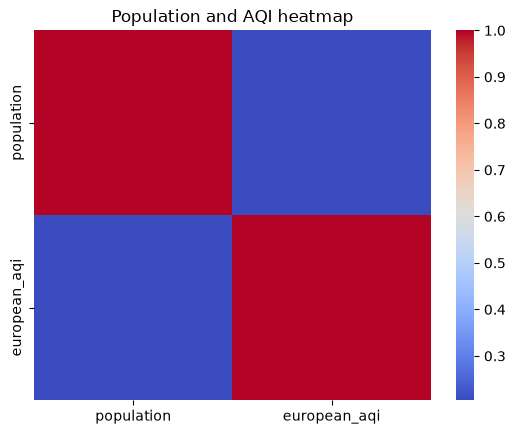

In [48]:
plt.title("Population and AQI heatmap")
sns.heatmap(data=corr, cmap="coolwarm");

There is no correlation between the population of cities and their air quality.

### Finding 3. Cities with the highest levels of fine particle pollution (PM 2.5 and PM 10)

The composition of the fine substance includes: pieces of soot, particles of mineral salts, heavy metal compounds, various allergens, plant pollen, bacteria, microorganisms and the remains of their vital activity, tobacco and exhaust smoke.

In [49]:
city_pm_stats = clean_df.groupby(
    by="Native"
).agg(
    pm10=("pm10", "mean"),
    pm2_5=("pm2_5", "mean")
)


In [50]:
city_pm_stats_sorted_by_pm10 = city_pm_stats.sort_values(by="pm10", ascending=False)

In [51]:
city_pm_stats_sorted_by_pm10.head()

,pm10,pm2_5
Native,,
Жаңаөзен,351.575000,68.277778
Алматы,36.326389,32.063889
Қаскелең,36.326389,32.063889
Жаркент,34.823611,12.825000
Шу,30.343056,29.323611


In [52]:
city_pm_stats_sorted_by_pm2_5 = city_pm_stats.sort_values(by="pm2_5", ascending=False)

In [53]:
city_pm_stats_sorted_by_pm2_5.head()

,pm10,pm2_5
Native,,
Жаңаөзен,351.575000,68.277778
Алматы,36.326389,32.063889
Қаскелең,36.326389,32.063889
Шу,30.343056,29.323611
Шымкент,30.343056,29.323611


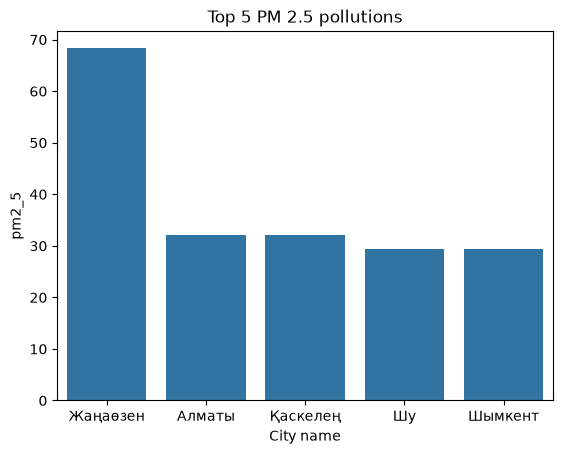

In [54]:
plt.title("Top 5 PM 2.5 pollutions");
sns.barplot(data=city_pm_stats_sorted_by_pm2_5.head(5), x="Native", y="pm2_5")
plt.xlabel("City name");

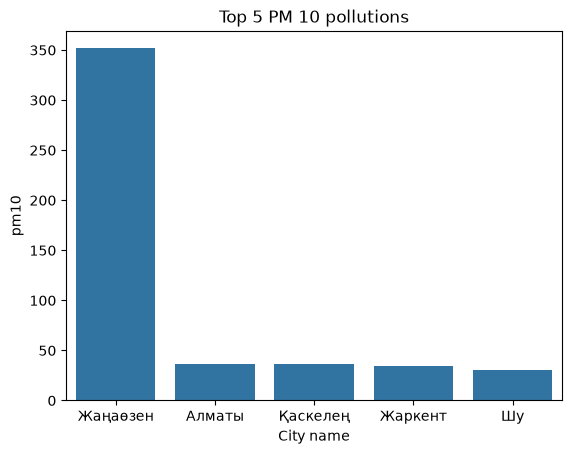

In [55]:
plt.title("Top 5 PM 10 pollutions");
sns.barplot(data=city_pm_stats_sorted_by_pm10.head(5), x="Native", y="pm10")
plt.xlabel("City name");

### Finding 4. How many people suffer from polluted air?

In [56]:
def categorize_aqi(aqi_index: float) -> str:
    aqi_categories = {
        "Good": (0, 20),
        "Fair": (20, 40),
        "Moderate": (40, 60),
        "Poor": (60, 80),
        "Very poor": (80, 100),
        "Extremely poor": (100, float("inf"))
    }
    for key, value in aqi_categories.items():
        if aqi_index >= value[0] and aqi_index < value[1]:
            return key

In [57]:
city_stats["aqi_category"] = city_stats["european_aqi"].apply(categorize_aqi)

In [58]:
city_stats.head()

,population,european_aqi,aqi_category
Name,,,
Abaı [Abay],28126,32.888889,Fair
Ajagóz [Ayagoz],40169,18.902778,Good
Alǵa,22365,32.666667,Fair
Almaty [Alma-Ata],2348103,50.458333,Moderate
Aqsaı [Aksay],35384,23.833333,Fair


In [59]:
city_stats_grouped_by_aqi_category = city_stats.groupby(
    by="aqi_category"
).agg(
    people=("population", "sum")
)

In [60]:
city_stats_grouped_by_aqi_category.sort_values(by="people")

,people
aqi_category,
Extremely poor,76430
Good,1716375
Moderate,4285571
Fair,5812557


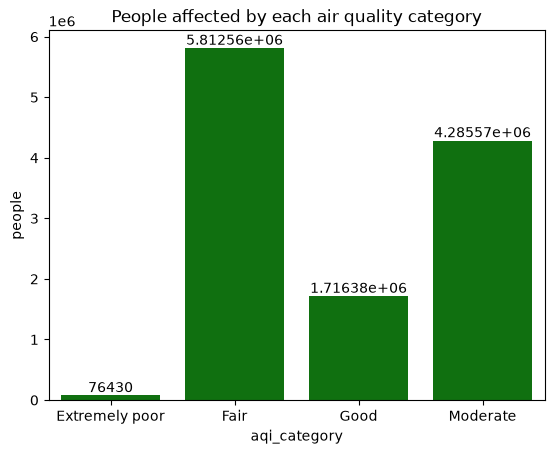

In [61]:
plt.title("People affected by each air quality category")
ax = sns.barplot(
    data=city_stats_grouped_by_aqi_category,
    x="aqi_category",
    y="people",
    color="g"
)
ax.bar_label(ax.containers[0]);

### Finding 5. Pollution of cities by burning fuel (coal, petrolium. e.g)

Carbon monoxide and nitrogen dioxide are the main emissions generated by the exhaust of vehicles using gasoline and other combustible fuels, as well as the operation of other engines. Burning other fuels for energy also releases carbon dioxide, sulfur dioxide, and methane into the atmosphere.

In [62]:
city_stats_transport_gasses = clean_df.groupby(
    by="Native"
).agg(
    carbon_monoxide=("carbon_monoxide", "mean"),
    carbon_dioxide=("carbon_dioxide", "mean"),
    nitrogen_dioxide=("nitrogen_dioxide", "mean"),
    sulphur_dioxide=("sulphur_dioxide", "mean"),
    methane=("methane", "mean"),
)

In [63]:
city_stats_transport_gasses.head()

,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,methane
Native,,,,,
Абай,137.125000,450.069444,5.456944,10.225000,1394.611111
Алматы,1641.472222,505.736111,31.350000,69.850000,1524.652778
Алға,239.708333,456.388889,8.208333,10.562500,1399.861111
Арал,122.458333,444.263889,1.402778,2.890278,1392.236111
Арыс,152.625000,446.791667,6.380556,12.819444,1403.861111


In [64]:
city_stats_transport_gasses.info()

<class 'pandas.DataFrame'>
Index: 66 entries, Абай to Өтеген батыр
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   carbon_monoxide   66 non-null     float64
 1   carbon_dioxide    66 non-null     float64
 2   nitrogen_dioxide  66 non-null     float64
 3   sulphur_dioxide   66 non-null     float64
 4   methane           66 non-null     float64
dtypes: float64(5)
memory usage: 4.0 KB


In [65]:
corr = city_stats_transport_gasses.corr()

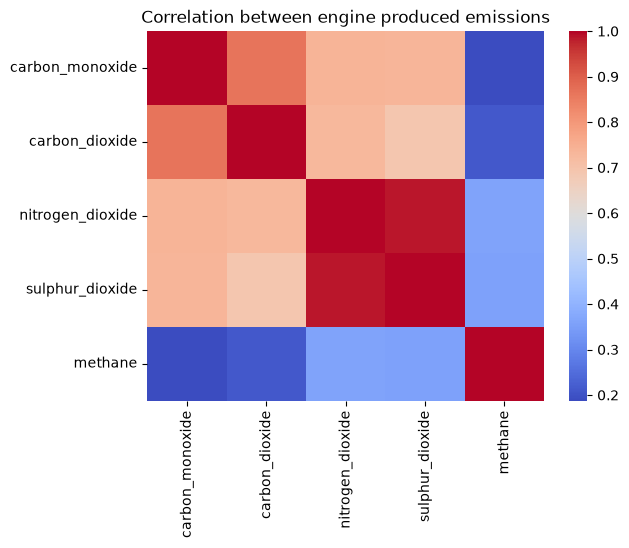

In [66]:
plt.title("Correlation between engine produced emissions")
sns.heatmap(corr, cmap="coolwarm");

Almost all gases except methane have a positive correlation. This means that the source of one gas is the source of all the others. If the correlation were close to 0, each gas would have its own individual source.

In [67]:
city_stats_transport_gasses.describe()

,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,methane
count,66.000000,66.000000,66.000000,66.000000,66.000000
mean,234.614268,451.978956,6.604146,11.950042,1473.112584
std,217.050351,10.785808,6.510898,14.512547,284.169606
min,107.097222,439.166667,0.641667,0.406944,1368.402778
25%,126.708333,443.993056,2.267014,2.862153,1389.038194
50%,163.743056,450.583333,4.456250,6.999306,1400.562500
75%,243.843750,458.312500,7.406944,13.167361,1426.034722
max,1641.472222,505.736111,31.350000,69.850000,3139.638889


In [68]:
city_stats_transport_gasses.idxmax()

carbon_monoxide     Алматы
carbon_dioxide      Алматы
nitrogen_dioxide    Алматы
sulphur_dioxide     Алматы
methane              Саран
dtype: str

Almaty is (almost) the leader in each of these points.

### Finding 6. How does the amount of emissions change throughout the day in Almaty

In [69]:
times = pd.DatetimeIndex(clean_df[clean_df["Native"] == "Алматы"]["time"])

In [70]:
almaty_pollution_df = clean_df[clean_df["Native"] == "Алматы"].groupby(by=times.hour).agg(
    carbon_monoxide=("carbon_monoxide", "mean"),
    carbon_dioxide=("carbon_dioxide", "mean"),
    nitrogen_dioxide=("nitrogen_dioxide", "mean"),
    sulphur_dioxide=("sulphur_dioxide", "mean"),
    methane=("methane", "mean"),
)

In [71]:
almaty_pollution_df

,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,methane
time,,,,,
0,2010.333333,524.333333,35.266667,70.566667,1552.333333
1,1526.000000,504.333333,33.533333,61.533333,1526.333333
2,1158.333333,489.333333,31.700000,54.300000,1508.666667
3,952.333333,481.666667,29.600000,49.166667,1502.333333
4,862.333333,479.000000,27.366667,45.900000,1504.666667
5,893.000000,479.666667,23.600000,32.833333,1510.666667
6,1149.000000,487.666667,23.233333,42.233333,1525.666667
7,1525.000000,499.666667,22.633333,55.133333,1544.333333
8,1712.666667,504.666667,22.133333,64.033333,1549.666667


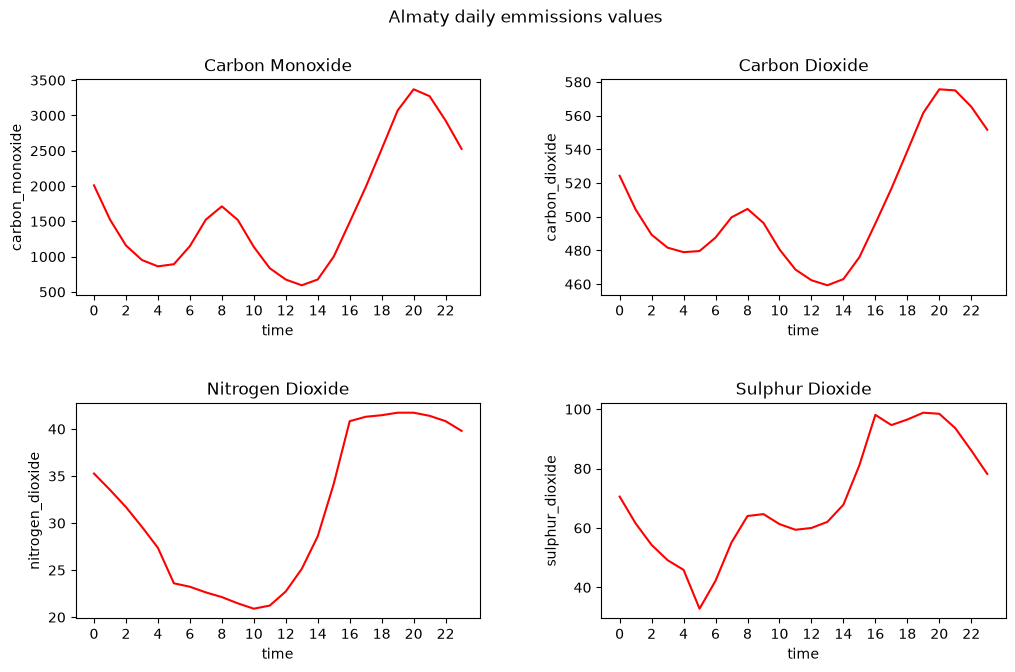

In [72]:
plt.suptitle("Almaty daily emmissions values")
plt.subplots_adjust(
    wspace=0.3,
    hspace=0.5
)

plt.subplot(2, 2, 1)
ax = sns.lineplot(
    data=almaty_pollution_df,
    x=almaty_pollution_df.index,
    y="carbon_monoxide",
    color="r"
);
plt.title("Carbon Monoxide")
ax.set_xticks(range(0, 24, 2))
ax.figure.set_size_inches(12, 7)

plt.subplot(2, 2, 2)
ax = sns.lineplot(
    data=almaty_pollution_df,
    x=almaty_pollution_df.index,
    y="carbon_dioxide",
    color="r"
);
plt.title("Carbon Dioxide")
ax.set_xticks(range(0, 24, 2))
ax.figure.set_size_inches(12, 7)

plt.subplot(2, 2, 3)
ax = sns.lineplot(
    data=almaty_pollution_df,
    x=almaty_pollution_df.index,
    y="nitrogen_dioxide",
    color="r"
);
plt.title("Nitrogen Dioxide")
ax.set_xticks(range(0, 24, 2))
ax.figure.set_size_inches(12, 7)

plt.subplot(2, 2, 4)
ax = sns.lineplot(
    data=almaty_pollution_df,
    x=almaty_pollution_df.index,
    y="sulphur_dioxide",
    color="r"
);
plt.title("Sulphur Dioxide")
ax.set_xticks(range(0, 24, 2))
ax.figure.set_size_inches(12, 7)

### Finding 7. The air quality of the regions of Kazakhstan and their population

In [73]:
region_df = clean_df.groupby(
    by=["Name", "Adm."]
).agg(
    aqi=("european_aqi", "mean"),
    population=("PopulationEstimate (E)2026-01-01", "first")
).reset_index().groupby(
    by="Adm."
).agg(
    aqi=("aqi", "mean"),
    population=("population", "sum")
)

In [74]:
region_df.info()

<class 'pandas.DataFrame'>
CategoricalIndex: 20 entries, AAK to ZHA
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   aqi         20 non-null     float64
 1   population  20 non-null     int32  
dtypes: float64(1), int32(1)
memory usage: 483.0 bytes


In [75]:
region_df.head()

,aqi,population
Adm.,,
AAK,50.458333,2348103
AAO,32.955556,286288
ABA,24.229167,355483
AQM,22.365741,230884
AQT,25.069444,683176


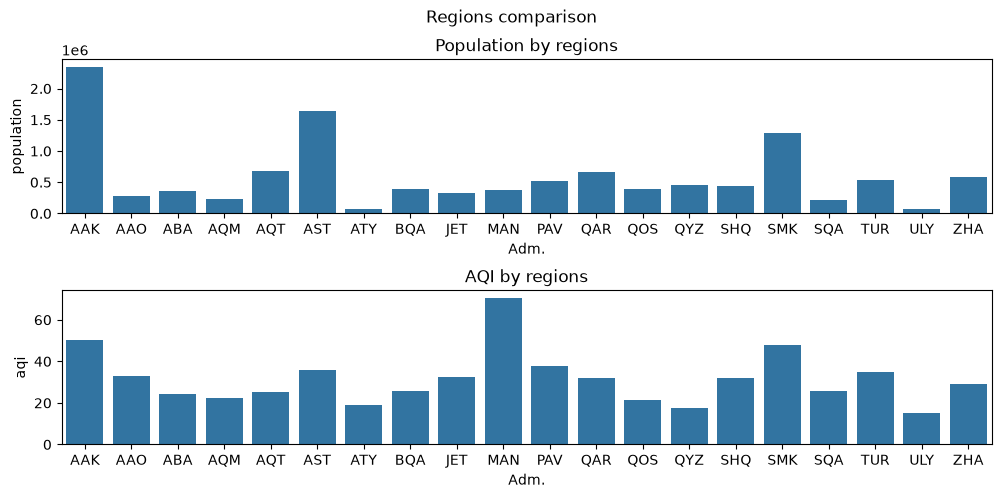

In [76]:
fig, ax = plt.subplots(2, 1, figsize=(12, 5))
plt.subplots_adjust(
    wspace=0.5,
    hspace=0.5
)
fig.suptitle("Regions comparison")

sns.barplot(
    data=region_df,
    x="Adm.",
    y="population",
    ax=ax[0]
);
ax[0].set_title("Population by regions");


sns.barplot(
    data=region_df,
    x="Adm.",
    y="aqi",
    ax=ax[1]
);
ax[1].set_title("AQI by regions");

### Finding 8. Daily particle count in Almaty and Zhanaozen

In [77]:
times = pd.DatetimeIndex(clean_df[(clean_df["Native"] == "Алматы") | (clean_df["Native"] == "Жаңаөзен")]["time"])

In [78]:
hourly_almaty_zhanaozen = clean_df[(clean_df["Native"] == "Алматы") | (clean_df["Native"] == "Жаңаөзен")].groupby(
    by=[times.hour, "Native"]
).agg(
    # Native=("Native", "first"),
    pm2_5=("pm2_5", "mean"),
    pm10=("pm10", "mean")  
)

In [79]:
hourly_almaty_zhanaozen.head()

pm2_5        pm10
time Native                          
0    Алматы     32.066667   35.100000
     Жаңаөзен  113.400000  585.500000
1    Алматы     28.733333   31.666667
     Жаңаөзен  109.100000  551.333333
2    Алматы     26.700000   29.700000

In [80]:
hourly_almaty_zhanaozen = hourly_almaty_zhanaozen.reset_index(level="Native")

In [81]:
hourly_almaty_zhanaozen.head()

,Native,pm2_5,pm10
time,,,
0,Алматы,32.066667,35.100000
0,Жаңаөзен,113.400000,585.500000
1,Алматы,28.733333,31.666667
1,Жаңаөзен,109.100000,551.333333
2,Алматы,26.700000,29.700000


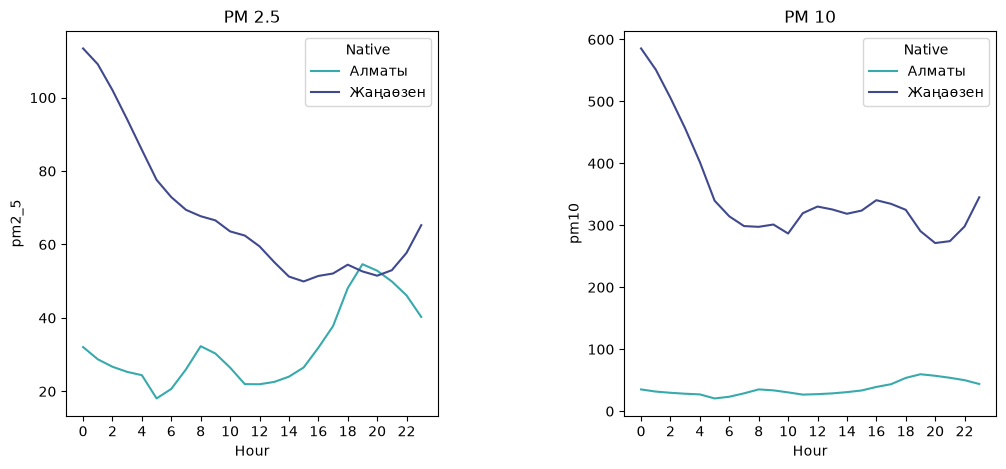

In [82]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
plt.subplots_adjust(
    wspace=0.5,
    hspace=0.5
)

palette = sns.color_palette("mako_r", 2)

hourly_almaty = hourly_almaty_zhanaozen[hourly_almaty_zhanaozen["Native"] == "Алматы"]

sns.lineplot(
    data=hourly_almaty_zhanaozen,
    x=hourly_almaty_zhanaozen.index,
    y="pm2_5",
    hue="Native",
    ax=ax[0],
    palette=palette
)
ax[0].set_title("PM 2.5")
ax[0].set_xlabel("Hour")
ax[0].set_xticks(range(0, 24, 2))

sns.lineplot(
    data=hourly_almaty_zhanaozen,
    x=hourly_almaty_zhanaozen.index,
    y="pm10",
    hue="Native",
    ax=ax[1],
    palette=palette
)
ax[1].set_title("PM 10")
ax[1].set_xlabel("Hour")
ax[1].set_xticks(range(0, 24, 2));